In [44]:
import pandas as pd
import numpy as np

In [45]:
from sklearn.datasets import fetch_california_housing

In [46]:
housing_data = fetch_california_housing(as_frame=True)

In [47]:
print(housing_data.DESCR)

.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group population
    - AveOccup      average number of household members
    - Latitude      block group latitude
    - Longitude     block group longitude

:Missing Attribute Values: None

This dataset was obtained from the StatLib repository.
https://www.dcc.fc.up.pt/~ltorgo/Regression/cal_housing.html

The target variable is the median house value for California districts,
expressed in hundreds of thousands of dollars ($100,000).

This dataset was derived from the 1990 U.S. census, using one row per ce

In [48]:
X = housing_data.data
y = housing_data.target

In [49]:
X.shape[0]

20640

In [50]:
X.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


In [51]:
y

0        4.526
1        3.585
2        3.521
3        3.413
4        3.422
         ...  
20635    0.781
20636    0.771
20637    0.923
20638    0.847
20639    0.894
Name: MedHouseVal, Length: 20640, dtype: float64

In [52]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler, MaxAbsScaler
from sklearn.compose import ColumnTransformer

# Feature Scaling Using ColumnTransformer

## Why Feature Scaling is Important

Many machine learning algorithms are sensitive to the scale of input features.  
If features have very different ranges, some features may dominate the learning process.

For example

Population may range from 1000 to 100000  
Latitude may range from 32 to 42  

Without scaling, the model may give excessive importance to Population simply because of its larger magnitude.

Feature scaling transforms variables so that they are comparable.

---

# StandardScaler

StandardScaler standardizes features so that they have mean equal to 0 and standard deviation equal to 1.

The transformation is

$$
z = \frac{x - \mu}{\sigma}
$$

where

$x$ is the original feature value  
$\mu$ is the mean of the feature  
$\sigma$ is the standard deviation of the feature  

This transformation centers the data around zero and scales variance.

StandardScaler works well when the data follows an approximately normal distribution.

---

# MinMaxScaler

MinMaxScaler rescales the feature to a fixed interval usually between 0 and 1.

The transformation is

$$
x_{scaled} = \frac{x - x_{min}}{x_{max} - x_{min}}
$$

where

$x_{min}$ is the minimum value of the feature  
$x_{max}$ is the maximum value of the feature  

This preserves the shape of the distribution but compresses the scale.

MinMaxScaler is commonly used for neural networks and distance based models.

---

# MaxAbsScaler

MaxAbsScaler scales features by dividing by the maximum absolute value.

The transformation is

$$
x_{scaled} = \frac{x}{|x_{max}|}
$$

This method keeps zero values unchanged and is useful for sparse data.

---

# ColumnTransformer

ColumnTransformer allows different preprocessing steps to be applied to different columns of a dataset.

Instead of applying the same scaler to every feature, we can apply

StandardScaler to some columns  
MinMaxScaler to others  
MaxAbsScaler to another group  

This is useful when different variables have different distributions or requirements.

In [53]:
# Create a list of tuples that defines which scaler will be applied to which columns
# Each tuple follows the format:
# (name_of_transformation, scaler_object, list_of_columns)

scalers = [
    # Apply StandardScaler to these columns
    # StandardScaler will standardize the features so that mean = 0 and standard deviation = 1
    ('SS', StandardScaler(), ['MedInc', 'HouseAge', 'AveRooms']),

    # Apply MinMaxScaler to these columns
    # MinMaxScaler rescales features to the range [0, 1]
    ('MMS', MinMaxScaler(), ['AveBedrms', 'Population', 'AveOccup']),

    # Apply MaxAbsScaler to these columns
    # MaxAbsScaler scales features by dividing by the maximum absolute value
    ('MAS', MaxAbsScaler(), ['Latitude', 'Longitude'])
]


# Create a ColumnTransformer object
# ColumnTransformer allows different preprocessing steps to be applied to different columns
ct = ColumnTransformer(

    scalers,
    # The list defined above tells the transformer which scaler to apply to which columns

    remainder='passthrough',
    # This means that any columns not listed in the scalers list will remain unchanged

    verbose_feature_names_out=False
    # Prevents sklearn from adding transformer prefixes to column names
)

# set_output(transform='pandas') ensures that the transformed output is returned as a pandas DataFrame
# instead of a NumPy array, which helps maintain column names
ct = ct.set_output(transform='pandas')

In [54]:
ct

ColumnTransformer(remainder='passthrough',
                  transformers=[('SS', StandardScaler(),
                                 ['MedInc', 'HouseAge', 'AveRooms']),
                                ('MMS', MinMaxScaler(),
                                 ['AveBedrms', 'Population', 'AveOccup']),
                                ('MAS', MaxAbsScaler(),
                                 ['Latitude', 'Longitude'])],
                  verbose_feature_names_out=False)

In [55]:
from sklearn.model_selection import train_test_split

In [56]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

In [57]:
0.25 * 20640

5160.0

In [58]:
print("Number of samples in training and test sets:", X_train.shape[0], "and Number of samples in test set:", X_test.shape[0])

Number of samples in training and test sets: 15480 and Number of samples in test set: 5160


In [59]:
X_train.shape

(15480, 8)

In [60]:
X_train.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
8158,4.2143,37.0,5.288235,0.973529,860.0,2.529412,33.81,-118.12
18368,5.3468,42.0,6.364322,1.087940,957.0,2.404523,37.16,-121.98
19197,3.9191,36.0,6.110063,1.059748,711.0,2.235849,38.45,-122.69
3746,6.3703,32.0,6.000000,0.990196,1159.0,2.272549,34.16,-118.41
13073,2.3684,17.0,4.795858,1.035503,706.0,2.088757,38.57,-121.33


In [61]:
X_train_tf = ct.fit_transform(X_train)
X_test_tf = ct.transform(X_test)

In [62]:
X_train_tf.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
8158,0.176489,0.666407,-0.060854,0.025301,0.024020,0.001478,0.805959,-0.949899
18368,0.771374,1.062889,0.383521,0.029823,0.026738,0.001378,0.885816,-0.980941
19197,0.021424,0.587111,0.278523,0.028709,0.019844,0.001242,0.916567,-0.986651
3746,1.309004,0.269925,0.233072,0.025960,0.032400,0.001272,0.814303,-0.952232
13073,-0.793136,-0.919520,-0.264184,0.027750,0.019703,0.001124,0.919428,-0.975714


In [63]:
X_test_tf.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
20046,-1.154112,-0.285149,-0.513467,0.027228,0.038930,0.002563,0.859595,-0.957057
3024,-0.707567,0.111332,-0.163619,0.033994,0.043779,0.001599,0.837664,-0.960676
15663,-0.209176,1.855852,-0.602271,0.033693,0.036632,0.000538,0.901073,-0.984640
20484,0.976656,-0.919520,0.300647,0.027146,0.047703,0.002215,0.817163,-0.954725
9814,-0.080534,0.428518,0.023700,0.027455,0.029709,0.001442,0.872944,-0.980539


## Linear Regression

In [64]:
from sklearn.linear_model import LinearRegression

In [65]:
lr = LinearRegression()
lr.fit(X_train_tf, y_train)

LinearRegression()

In [66]:
lr.score(X_test_tf, y_test) #R2 score

0.5910509795491352

In [67]:
lr.coef_

array([ 8.52108147e-01,  1.20655325e-01, -3.02105554e-01,  2.01025302e+01,
       -5.13430073e-02, -4.27851237e+00, -1.75583930e+01, -5.38939286e+01])

In [68]:
lr.intercept_

-35.433988507198

In [69]:
lr1 = LinearRegression(fit_intercept=False)
lr1.fit(X_train_tf, y_train)

LinearRegression(fit_intercept=False)

In [70]:
lr1.intercept_

0.0

In [71]:
lr1.score(X_test_tf, y_test)

0.5397727035518555

#### Hyper-parameter tuning

In [72]:
from sklearn.model_selection import GridSearchCV

In [73]:
# Define a dictionary that specifies the hyperparameters
# and the values that GridSearchCV should test

param_grid_lr = {

    'fit_intercept': [True, False],
    # This parameter determines whether the regression model
    # should learn an intercept term (beta_0) in the equation

    'copy_X': [True, False],
    # If True the input data will be copied internally
    # If False the model may overwrite the original data during computations
    # This mainly affects memory usage and computational efficiency

    'n_jobs': [None, -1],
    # Controls the number of CPU cores used during computation
    # None means use a single core
    # -1 means use all available cores

    'positive': [True, False]
    # If True the model forces all coefficients to be non negative
    # If False coefficients can be either positive or negative
}

# Hyperparameter Optimization Using GridSearchCV

Machine learning models often contain parameters that must be chosen before training.  
These are called **hyperparameters**.

Examples for Linear Regression based models may include

regularization strength  
polynomial degree  
fit intercept options  

Choosing good hyperparameters is important because they directly affect model performance.

GridSearchCV is a method that systematically searches for the best combination of hyperparameters.

---

# What Grid Search Does

Grid search creates a grid of possible parameter values and trains the model for every combination.

For example if we have

parameter A = {1, 2}

parameter B = {0.1, 0.01}

The grid becomes

(1 , 0.1)  
(1 , 0.01)  
(2 , 0.1)  
(2 , 0.01)

The model is trained four times.

The best performing combination is selected.

---

# Cross Validation

GridSearchCV uses **cross validation** to evaluate each hyperparameter combination.

If we use

cv = 5

the dataset is divided into 5 folds.

Training and validation happen as follows

Fold 1 used for validation, remaining 4 used for training  
Fold 2 used for validation, remaining 4 used for training  
Fold 3 used for validation, remaining 4 used for training  
Fold 4 used for validation, remaining 4 used for training  
Fold 5 used for validation, remaining 4 used for training  

The final score is the **average across all folds**.

*For each combination of hyperparameters, the model is trained and evaluated using cross validation.*

---

# Mathematical Idea of Cross Validation

If the score for each fold is

$$
s_1, s_2, s_3, s_4, s_5
$$

The final cross validation score is

$$
\frac{s_1 + s_2 + s_3 + s_4 + s_5}{5}
$$

This provides a more reliable estimate of model performance compared to a single train test split.

---

# Why GridSearchCV Is Useful

Advantages

-   Finds optimal hyperparameters  
-   Reduces manual trial and error  
-   Uses cross validation for reliable evaluation  
-   Prevents overfitting to a single split

Disadvantages

-   Computationally expensive  
-   Number of model trainings increases quickly as parameter combinations increase

---

# Output of GridSearchCV

After training, GridSearchCV provides

-   best parameters found  
-   best cross validation score  
-   fully trained best model

These can be accessed using

best_params_  
best_score_  
best_estimator_

In [74]:
gscv_lr = GridSearchCV(lr, param_grid=param_grid_lr, cv=5)
gscv_lr.fit(X_train_tf, y_train)
gscv_lr

GridSearchCV(cv=5, estimator=LinearRegression(),
             param_grid={'copy_X': [True, False],
                         'fit_intercept': [True, False], 'n_jobs': [None, -1],
                         'positive': [True, False]})

In [75]:
gscv_lr.best_params_

{'copy_X': True, 'fit_intercept': True, 'n_jobs': None, 'positive': False}

In [76]:
gscv_lr.best_score_

0.6071599686932019

In [77]:
gscv_lr.best_estimator_

LinearRegression()

In [78]:
best_model_lr = gscv_lr.best_estimator_

In [79]:
best_model_lr.score(X_test_tf, y_test)

0.5910509795491352

# Stochastic Gradient Descent Regressor

SGDRegressor is a linear regression model that learns model parameters using **Stochastic Gradient Descent** instead of solving the normal equation directly.

This approach is especially useful for large datasets.

---

# Linear Regression Objective

In linear regression the goal is to find coefficients that minimize the Mean Squared Error.

The prediction equation is

$$
\hat{y} = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + ... + \beta_p x_p
$$

The model tries to minimize the cost function

$$
J(\beta) = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2
$$

where

$y_i$ is the actual value  
$\hat{y}_i$ is the predicted value

---

# Gradient Descent

Gradient Descent is an optimization algorithm used to minimize the loss function.

The parameters are updated iteratively using the rule

$$
\beta_j = \beta_j - \eta \frac{\partial J}{\partial \beta_j}
$$

where

$\eta$ is the learning rate  
$\frac{\partial J}{\partial \beta_j}$ is the gradient of the loss with respect to the parameter

---

# Stochastic Gradient Descent

In standard gradient descent the gradient is computed using the entire dataset.

In **Stochastic Gradient Descent**, the model updates parameters using **one training example at a time**.

This makes the training process faster and scalable for very large datasets.

Update rule becomes

$$
\beta = \beta - \eta \nabla J_i(\beta)
$$

where the gradient is computed using a single sample $i$.

---

# Advantages of SGD

Works well with very large datasets  
Requires less memory  
Allows online learning

---

# Disadvantages

Training may be noisy because updates are based on single samples  
Requires careful tuning of learning rate

In [ ]:
#  Sklearn API's for Regression Tasks
df.drop(columns="id", inplace=True)
df.head()

,Gender,Age,HasTension,AnyHeartDisease,ever_married,Occupation,LivesIn,GlucoseLevel,BMI,SmokingStatus,HeartAttack
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [80]:
from sklearn.linear_model import SGDRegressor

In [81]:
sgd = SGDRegressor(random_state=42)

In [82]:
sgd.fit(X_train_tf, y_train)
sgd.score(X_test_tf, y_test)

0.5088569210987615

- loss = ['squared_error', 'huber']
- penalty = [l1, l2]
- warm_start = [True, False]
- alpha = [0.1, 0.001, 0.01]
- fit_intercept = [True, False]
- max_iter = [500, 750, 1000, 2000, 5000]

# Ridge Regression (L2 Regularization)

## Why Do We Need Regularization?

When models become too flexible (many features, polynomial terms),
they may overfit.

Regularization adds a penalty to large coefficients.

---

## Ridge Regression Formula

$$
Loss = MSE + \lambda \sum \beta^2
$$

Where:
- $\lambda$ controls penalty strength
- Large $\lambda$ -> stronger shrinkage

---

## How It Works

Ridge:

- Shrinks coefficients toward zero
- Reduces model complexity
- Keeps all features but reduces impact

It does NOT remove features completely.

---

## Advantages

 Reduces overfitting  
 Handles multicollinearity well  
 More stable model  

---

## Disadvantages

 Does not perform feature selection  
 Interpretation becomes less direct  

---

##  When to Use

- When many correlated features exist
- When polynomial features are used
- When overfitting is suspected

#  Lasso Regression (L1 Regularization)

## What Makes Lasso Different?

Lasso adds an absolute value penalty:

$$
Loss = MSE + \lambda \sum |\beta|
$$

---

## How It Works

Lasso:

- Shrinks some coefficients
- Can make some coefficients exactly zero
- Performs automatic feature selection

This makes it useful for high-dimensional datasets.

---

## Advantages

 Performs feature selection  
 Reduces overfitting  
 Produces sparse models  

---

## Disadvantages

 Can remove important correlated features  
 Less stable when features are highly correlated  

---

## When to Use

- When many features exist
- When feature selection is needed
- When interpretability matters

In [83]:
from sklearn.linear_model import Ridge, Lasso

In [84]:
ridge = Ridge(random_state=42)
ridge.fit(X_train_tf, y_train)

Ridge(random_state=42)

In [85]:
lasso = Lasso(random_state=42)
lasso.fit(X_train_tf, y_train)

Lasso(random_state=42)

In [86]:
? LinearRegression

Init signature:
 LinearRegression(
    *,
    fit_intercept=True,
    copy_X=True,
    n_jobs=None,
    positive=False,
)
Docstring:     
Ordinary least squares Linear Regression.

LinearRegression fits a linear model with coefficients w = (w1, ..., wp)
to minimize the residual sum of squares between the observed targets in
the dataset, and the targets predicted by the linear approximation.

Parameters
----------
fit_intercept : bool, default=True
    Whether to calculate the intercept for this model. If set
    to False, no intercept will be used in calculations
    (i.e. data is expected to be centered).

copy_X : bool, default=True
    If True, X will be copied; else, it may be overwritten.

n_jobs : int, default=None
    The number of jobs to use for the computation. This will only provide
    speedup in case of sufficiently large problems, that is if firstly
    `n_targets > 1` and secondly `X` is sparse or if `positive` is set
    to `True`. ``None`` means 1 unless in a
    :obj:

In [87]:
ridge.score(X_test_tf, y_test)

0.5666397616061717

In [88]:
lasso.score(X_test_tf, y_test)

-3.8775657694056775e-05

# Support Vector Regression

Support Vector Regression is a regression technique derived from Support Vector Machines.

Instead of minimizing only the prediction error, SVR attempts to fit a function such that errors remain within a specified tolerance.

This tolerance is controlled by a parameter called epsilon.

---

# Idea Behind Support Vector Regression

The goal is to find a function that approximates the relationship between input features and the target variable.

The regression function can be written as

$$
f(x) = w^T x + b
$$

where

$x$ represents the input feature vector  
$w$ represents the weight vector  
$b$ represents the bias term

---

# LinearSVR

LinearSVR is a faster implementation of Support Vector Regression when the relationship between features and target is approximately linear.

The model still follows the same SVR principle but uses a linear function instead of kernel transformations.

---

# Difference Between SVR and LinearSVR

SVR

Can use kernel functions  
Can model nonlinear relationships  
More computationally expensive

LinearSVR

Uses a linear model  
Faster on large datasets  
Suitable when data relationships are approximately linear

---

# Kernel Trick in SVR

SVR can transform input data into higher dimensional space using kernel functions.

Common kernels include

Linear kernel

$$
K(x_i, x_j) = x_i^T x_j
$$

Polynomial kernel

$$
K(x_i, x_j) = (x_i^T x_j + c)^d
$$

These kernels allow SVR to capture nonlinear patterns in data.

In [89]:
from sklearn.svm import SVR, LinearSVR

In [90]:
svr = SVR()
l_svr = LinearSVR(random_state=42)

In [91]:
svr.fit(X_train_tf, y_train)
svr.score(X_test_tf, y_test)

0.5879010711040904

In [92]:
l_svr.fit(X_train_tf, y_train)
l_svr.score(X_test_tf, y_test)

0.5443614802040695

In [93]:
l_svr.coef_

array([  0.94989596,   0.13416051,  -0.28244342,  11.99779576,
         0.42235366,  -3.60467152,  -5.36386896, -14.31536645])

# Decision Tree Regression

Decision Tree Regression is a non parametric supervised learning algorithm used for predicting continuous target variables.

The model works by recursively splitting the feature space into smaller regions and making predictions based on the average value of the target variable in those regions.

---

# Basic Idea

The algorithm constructs a tree structure consisting of

Root node  
Internal decision nodes  
Leaf nodes

Each internal node represents a decision rule on a feature.

Each leaf node contains the predicted output value.

---

# Example of a Decision Rule

A node might split data based on a condition such as

$$
\text{HouseAge} < 20
$$

All samples satisfying the condition go to the left branch.

All samples that do not satisfy the condition go to the right branch.

This process continues recursively until stopping conditions are met.

---

# Prediction in Decision Trees

For regression tasks, the prediction at a leaf node is typically the **mean of the target values** of training samples that fall into that leaf.

If a leaf contains samples

$$
y_1, y_2, ..., y_k
$$

then the predicted value is

$$
\hat{y} = \frac{1}{k} \sum_{i=1}^{k} y_i
$$

---

# Splitting Criterion

To decide the best split, the algorithm minimizes the Mean Squared Error of the resulting partitions.

Mean Squared Error is defined as

$$
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \bar{y})^2
$$

where

$y_i$ is the actual value  
$\bar{y}$ is the mean target value in the node

The algorithm chooses the split that results in the **largest reduction in MSE**.

---

# Advantages of Decision Tree Regression

Can capture nonlinear relationships  
No need for feature scaling  
Easy to interpret and visualize

---

# Disadvantages

Prone to overfitting if the tree becomes too deep  
Sensitive to small variations in the data  
Can produce unstable models

---

# Controlling Overfitting

Decision trees can be regularized using parameters such as

max_depth  
min_samples_split  
min_samples_leaf

These parameters control the complexity of the tree.

In [94]:
from sklearn.tree import DecisionTreeRegressor

In [95]:
dt = DecisionTreeRegressor(random_state=42)
dt.fit(X_train_tf, y_train)

DecisionTreeRegressor(random_state=42)

In [96]:
dt.score(X_test_tf, y_test)

0.6020304523433868

In [97]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

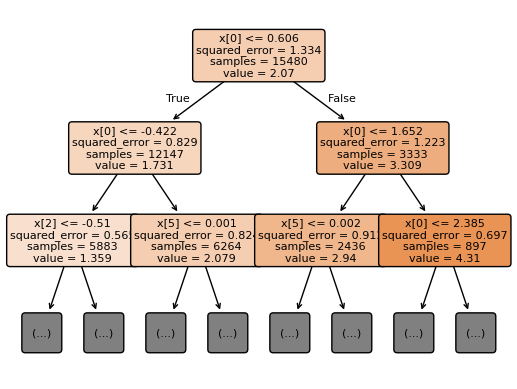

In [98]:
plot_tree(dt, max_depth=2, filled=True, rounded=True, fontsize=8);
# plt.figure(figsize=(20,20))
plt.show()

In [99]:
dt.tree_

In [100]:
dt.tree_?

Type:        Tree
String form: <sklearn.tree._tree.Tree object at 0x000002265BB2C340>
File:        c:\users\anish\anaconda3\lib\site-packages\sklearn\tree\_tree.cp312-win_amd64.pyd
Docstring:  
Array-based representation of a binary decision tree.

The binary tree is represented as a number of parallel arrays. The i-th
element of each array holds information about the node `i`. Node 0 is the
tree's root. You can find a detailed description of all arrays in
`_tree.pxd`. NOTE: Some of the arrays only apply to either leaves or split
nodes, resp. In this case the values of nodes of the other type are
arbitrary!

Attributes
----------
node_count : intp_t
    The number of nodes (internal nodes + leaves) in the tree.

capacity : intp_t
    The current capacity (i.e., size) of the arrays, which is at least as
    great as `node_count`.

max_depth : intp_t
    The depth of the tree, i.e. the maximum depth of its leaves.

children_left : array of intp_t, shape [node_count]
    children_left[i] 

In [101]:
dt.tree_.max_depth

36

In [102]:
dt.tree_.children_right

array([23916, 11591,  4236, ...,    -1,    -1,    -1], dtype=int64)

### HPT of Decision Tree Regressor


```
criterion  ['squared_error','absolute_error']
splitter ['best','random']
min_samples_split [2,5,7]
min_samples_leaf [2, 5 ,9]
max_features ['sqrt',1, 0.4,'log2']
max_leaf_nodes [5, 10, 12, 15]
```

In [103]:
param_grid_dt = {
    "criterion":['squared_error', 'absolute_error'],
    "splitter":['best', 'random'],
    "min_samples_split":[2,5,7],
    "min_samples_leaf":[2,5,9],
    "max_features":['sqrt',1,0.4,'log2'],
    "max_leaf_nodes":[5,10,12,15]
}

In [104]:
grid_dt = GridSearchCV(dt, param_grid=param_grid_dt,cv=5)
grid_dt.fit(X_train_tf, y_train)
grid_dt

c:\Users\anish\anaconda3\Lib\site-packages\numpy\ma\core.py:2820: RuntimeWarning: invalid value encountered in cast
  _data = np.array(data, dtype=dtype, copy=copy,


GridSearchCV(cv=5, estimator=DecisionTreeRegressor(random_state=42),
             param_grid={'criterion': ['squared_error', 'absolute_error'],
                         'max_features': ['sqrt', 1, 0.4, 'log2'],
                         'max_leaf_nodes': [5, 10, 12, 15],
                         'min_samples_leaf': [2, 5, 9],
                         'min_samples_split': [2, 5, 7],
                         'splitter': ['best', 'random']})

# Ensemble techniques

# AdaBoost Regression

AdaBoost stands for Adaptive Boosting.  
It is an ensemble learning technique that combines multiple weak learners to create a strong predictive model.

In regression problems, AdaBoostRegressor typically uses decision trees as base learners and improves predictions by focusing more on difficult samples.

---

# Idea Behind Boosting

Boosting is based on the idea that many weak models can be combined to form a strong model.

A weak learner is a model that performs only slightly better than random prediction.

AdaBoost builds models sequentially.

Each new model focuses more on the samples that previous models predicted poorly.

---

# Mathematical Intuition

Suppose we train several weak models

$$
f_1(x), f_2(x), ..., f_T(x)
$$

The final prediction is a weighted sum of all these models

$$
F(x) = \sum_{t=1}^{T} \alpha_t f_t(x)
$$

where

$\alpha_t$ represents the importance weight of each weak learner.

---

# Weight Updating Mechanism

After each model is trained

samples with larger prediction errors receive higher weights

samples with smaller errors receive lower weights

This means the next learner focuses more on difficult observations.

---

# Learning Process

Step 1  
Initialize all training sample weights equally.

Step 2  
Train a weak learner.

Step 3  
Measure prediction error.

Step 4  
Increase the weights of mispredicted samples.

Step 5  
Train the next learner using the updated weights.

This process repeats until the specified number of estimators is reached.

---

# Why AdaBoost Works

Each model corrects the mistakes of the previous model.

As more models are added, prediction accuracy improves.

---

# Advantages

Captures complex patterns by combining many weak models  
Works well with decision trees  
Often improves performance compared to a single model

Reduces Bias

---

# Disadvantages

Sensitive to noisy data and outliers  
Training may become slower with many estimators  
Requires careful tuning of hyperparameters

In [105]:
from sklearn.ensemble import AdaBoostRegressor

In [106]:
boost = AdaBoostRegressor(random_state=42)
boost.fit(X_train_tf, y_train)
boost.score(X_test_tf, y_test)

0.4501310151919852

# Bagging Regressor

Bagging stands for **Bootstrap Aggregating**.  
It is an ensemble learning technique used to improve model stability and reduce variance.

Instead of training one model on the full dataset, bagging trains multiple models on different **bootstrap samples** and then combines their predictions.

---

## Bootstrap Sampling

Bootstrap sampling means sampling **with replacement** from the original dataset.

If the dataset has $n$ observations, each bootstrap sample also contains $n$ observations.

Example:

Original dataset

$$
D = \{x_1, x_2, x_3, x_4, x_5\}
$$

A possible bootstrap sample could be

$$
D_1 = \{x_2, x_5, x_5, x_1, x_3\}
$$

Some observations may appear multiple times while some may not appear at all.

---

## Training Multiple Models

Suppose we train $T$ base models.

$$
f_1(x), f_2(x), f_3(x), \ldots, f_T(x)
$$

Each model is trained on a different bootstrap sample.

Because each sample is slightly different, each model learns slightly different patterns.

---

## Final Prediction

For regression problems, the final prediction is the **average prediction** from all models.

$$
\hat{f}(x) = \frac{1}{T} \sum_{t=1}^{T} f_t(x)
$$

This averaging reduces prediction instability.

---

## Why Bagging Reduces Variance

Some models such as decision trees have **high variance**.  
Small changes in the training data can produce very different models.

By training many models and averaging their predictions, bagging stabilizes the final prediction.

---

## Advantages

Reduces model variance  
Improves prediction stability  
Works well with high variance models such as decision trees  
Often improves overall model performance

---

## Disadvantages

Requires training multiple models  
Higher computational cost  
Less interpretable compared to a single model

---

## Relationship to Random Forest

Random Forest is an extension of Bagging where two ideas are used:

1. Bootstrap sampling of data  
2. Random selection of features during splits

This increases diversity among trees and further reduces variance.

In [107]:
from sklearn.ensemble import BaggingRegressor

In [108]:
bag = BaggingRegressor(random_state=42)
bag.fit(X_train_tf, y_train)
bag.score(X_test_tf, y_test)

0.7872185720731277

# Random Forest Regression

Random Forest is an ensemble learning method that combines multiple decision trees to improve predictive performance and reduce overfitting.

Instead of relying on a single decision tree, Random Forest trains many decision trees on different subsets of the data and averages their predictions.

This approach reduces variance and increases model stability.

---

## Idea Behind Random Forest

Random Forest combines two important ideas

Bootstrap Sampling  
Random Feature Selection

Each decision tree is trained on a randomly sampled dataset and at each split the algorithm considers only a random subset of features.

This randomness increases diversity among trees.

---

## Bootstrap Sampling

If the dataset contains $n$ observations, a bootstrap sample is created by sampling $n$ observations with replacement.

Example dataset

$$
D = \{x_1, x_2, x_3, x_4, x_5\}
$$

Example bootstrap sample

$$
D_1 = \{x_3, x_1, x_5, x_5, x_2\}
$$

Each tree in the forest receives a different bootstrap sample.

---

## Training Multiple Trees

Suppose the forest contains $T$ decision trees

$$
f_1(x), f_2(x), f_3(x), ..., f_T(x)
$$

Each tree learns a slightly different structure because of different training samples and random feature selection.

---

## Final Prediction

For regression problems, Random Forest predicts by averaging the outputs of all trees.

$$
\hat{f}(x) = \frac{1}{T} \sum_{t=1}^{T} f_t(x)
$$

This averaging reduces the variance of the model.

---

## Why Random Forest Works

Decision trees are high variance models.  
Small changes in the dataset can produce very different trees.

Random Forest stabilizes predictions by averaging many trees trained on different data samples.

---

## Advantages

Reduces overfitting compared to a single decision tree  
Handles nonlinear relationships well  
Works well with large datasets  
Automatically captures feature interactions

---

## Disadvantages

Less interpretable than a single decision tree  
Requires more computational resources  
Large forests can increase training time

In [109]:
from sklearn.ensemble import RandomForestRegressor

In [110]:
rf = RandomForestRegressor(random_state=42)
rf.fit(X_train_tf, y_train)
rf.score(X_test_tf, y_test)

0.8073150590580744

# Multilayer Perceptron Regressor

Multilayer Perceptron Regressor is a neural network based regression model.  
It belongs to the family of Artificial Neural Networks and is designed to model complex nonlinear relationships between input features and the target variable.

The model consists of multiple layers of interconnected neurons.

Typical structure of a neural network

Input layer  
Hidden layers  
Output layer

Each neuron receives inputs, applies weights, adds a bias, and passes the result through an activation function.

---

## Mathematical Representation of a Neuron

A neuron computes a weighted sum of inputs and applies an activation function.

$$
z = w_1 x_1 + w_2 x_2 + ... + w_n x_n + b
$$

where

$x_1, x_2, ..., x_n$ are input features  
$w_1, w_2, ..., w_n$ are weights  
$b$ is the bias term

The neuron output becomes

$$
a = \phi(z)
$$

where $\phi$ is the activation function.

---

## Forward Propagation

During forward propagation the input moves through the network layer by layer.

For a hidden layer

$$
a^{(l)} = \phi(W^{(l)} a^{(l-1)} + b^{(l)})
$$

where

$W^{(l)}$ is the weight matrix  
$a^{(l-1)}$ is the output of the previous layer  
$b^{(l)}$ is the bias vector

---

## Loss Function

For regression tasks the network typically minimizes Mean Squared Error.

$$
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2
$$

where

$y_i$ is the actual value  
$\hat{y}_i$ is the predicted value

---

## Backpropagation

The network learns by adjusting weights using gradient descent.

Weights are updated using

$$
w = w - \eta \frac{\partial L}{\partial w}
$$

where

$\eta$ is the learning rate  
$L$ is the loss function

Backpropagation computes gradients of the loss with respect to each weight.

---

## Advantages

Can model highly complex nonlinear relationships  
Automatically learns feature interactions  
Very flexible model structure

---

## Disadvantages

Requires careful tuning of hyperparameters  
Training can be computationally expensive  
Less interpretable than simpler models

In [111]:
from sklearn.neural_network import MLPRegressor

In [112]:
import warnings
warnings.filterwarnings('ignore')

In [113]:
mlpr = MLPRegressor(random_state=42)
mlpr.fit(X_train_tf, y_train)
mlpr.score(X_test_tf, y_test)

0.6293128081376547

# Difference Between Bagging and Boosting

Bagging and Boosting are ensemble learning techniques that combine multiple models to improve predictive performance.  
However, they differ in how models are trained and how errors are handled.

---

## Bagging (Bootstrap Aggregating)

Bagging reduces model variance by training multiple models independently on different bootstrap samples of the dataset.

Bootstrap sampling means sampling **with replacement** from the training data.  
Each model is trained on a slightly different version of the dataset.

If we train \(T\) models

$$
f_1(x), f_2(x), f_3(x), \ldots, f_T(x)
$$

then the final prediction for regression problems is the **average** of predictions:

$$
\hat{f}(x) = \frac{1}{T} \sum_{t=1}^{T} f_t(x)
$$

This averaging stabilizes predictions and reduces variance.

### Characteristics of Bagging

Models are trained independently  
Training can be parallelized  
Main goal is variance reduction  
Works well with high variance models such as decision trees

### Examples in scikit learn

BaggingRegressor  
RandomForestRegressor  
ExtraTreesRegressor

Random Forest is an extension of bagging where feature randomness is also introduced during tree splitting.

---

## Boosting

Boosting reduces bias by training models sequentially.  
Each new model focuses more on correcting the errors made by previous models.

The final prediction is a weighted combination of all models.

$$
F(x) = \sum_{t=1}^{T} \alpha_t f_t(x)
$$

where \(f_t(x)\) are weak learners and \(\alpha_t\) are their weights.

Boosting gradually improves the model by focusing on difficult samples.

### Characteristics of Boosting

Models are trained sequentially  
Each model corrects previous mistakes  
Main goal is bias reduction  
More sensitive to noise and outliers

### Examples in scikit learn

AdaBoostRegressor  
GradientBoostingRegressor  
HistGradientBoostingRegressor

---

## Key Differences

Training strategy

Bagging trains models independently  
Boosting trains models sequentially

Goal

Bagging reduces variance  
Boosting reduces bias

Handling errors

Bagging treats all samples equally  
Boosting increases importance of mispredicted samples

Parallelization

Bagging can be parallelized  
Boosting cannot easily be parallelized because models depend on previous ones